AI VISION LAB · 6–7강 통합 프로젝트

MISSION 02

# 특성 추가 전후의
모델 성능 비교하기

새 특성 하나가 모델의 판단을 얼마나 바꿀까?

권장 학습 시간 · 약 3~4시간실습 환경 · Google Colab데이터 · wafer_features.pkl

## 이번 미션에서 해결할 문제

미션 01에서는 웨이퍼맵 배열에서 두 가지 특성을 추출했습니다.

- **defect_ratio:** 전체 유효 칩 중 불량 칩의 비율
- **edge_ratio:** 가장자리 유효 칩 중 불량 칩의 비율

두 특성은 모두 불량과 관련된 정보를 나타내지만 서로 다른 특징을 표현합니다.

그렇다면 새로운 특성을 추가하면 분류 모델의 성능이 실제로 좋아질까요?

특성이 많아질수록 항상 성능이 좋아지는 것은 아닙니다. 추가한 특성이 기존 특성과 비슷한 정보를 제공하거나, 불량 유형을 구분하는 데 별 도움이 되지 않을 수도 있습니다.

이번 미션에서는 동일한 분류 모델을 두 번 학습시킵니다.

| 구분 | 기준 모델 A | 비교 모델 B |
| --- | --- | --- |
| 입력 특성 | defect_ratio | defect_ratio + edge_ratio |
| 분류 알고리즘 | RandomForest | RandomForest |
| 학습·테스트 데이터 | 동일 | 동일 |
| 난수 시드 | 42 | 42 |
| 평가 지표 | Accuracy, Macro F1 | Accuracy, Macro F1 |

두 실험의 차이는 **edge_ratio 특성의 추가 여부**입니다.

이번 미션을 완료하면 다음을 할 수 있습니다.

- 실험 조건을 통제해야 하는 이유를 설명할 수 있습니다.
- 난수 시드를 고정하고 동일한 데이터를 사용해 모델을 비교할 수 있습니다.
- 특성 추가 전후의 정확도와 Macro F1-score를 비교할 수 있습니다.
- 혼동행렬을 이용해 어떤 불량 유형에서 성능이 달라졌는지 분석할 수 있습니다.
- 실험 결과를 바탕으로 새로운 특성의 유용성을 판단할 수 있습니다.

**질문과 보고서 안내:** 모든 질문에 대한 답을 보고서에 포함할 필요는 없습니다. **[필수 기록]** 질문은 실습 중 답을 남겨 두고, 최종 보고서에는 실험 결과와 분석을 중심으로 정리하세요.

## 알아두기. 공정한 실험과 재현성

### 1. 무엇을 비교하고 있는가?

샤인머스켓 농장에서 포도의 당도를 높이는 방법을 연구한다고 가정해 봅시다.

농장에서는 포도의 당도에 여러 요소가 영향을 미칠 수 있다고 생각하고 있습니다.

- **영양제:** 특정 영양제를 사용하면 당도가 높아질까?
- **온도:** 비닐하우스의 온도가 당도에 영향을 줄까?
- **물의 양:** 물을 많이 주거나 적게 주면 당도가 달라질까?

농장에서는 새로운 영양제의 효과를 확인하기 위해 두 구역에서 샤인머스켓을 재배했습니다.

| 조건 | 재배 구역 A | 재배 구역 B |
| --- | --- | --- |
| 영양제 | 사용하지 않음 | 사용함 |
| 비닐하우스 온도 | 25℃ | 30℃ |
| 하루 물 공급량 | 2L | 3L |
| 수확한 포도의 당도 | 17 Brix | 20 Brix |

재배 구역 B에서 수확한 포도의 당도가 더 높았습니다.

**그렇다면 영양제 덕분에 당도가 3 Brix 높아졌다고 결론 내릴 수 있을까요?**

그렇게 판단하기는 어렵습니다. 영양제뿐 아니라 온도와 물의 양도 달랐기 때문입니다.

영양제의 효과를 확인하려면 두 구역의 온도와 물 공급량 등 다른 조건을 가능한 한 동일하게 유지하고, **영양제 사용 여부만 다르게 설정**해야 합니다.

머신러닝 실험도 마찬가지입니다.

이번 실습에서는 새로운 특성인 `edge_ratio`를 추가했을 때 분류 성능이 어떻게 달라지는지 확인하려고 합니다.

따라서 다음 조건을 동일하게 유지합니다.

- 같은 데이터를 사용합니다.
- 학습 데이터와 테스트 데이터를 동일하게 나눕니다.
- 같은 분류 알고리즘을 사용합니다.
- 모델의 하이퍼파라미터를 동일하게 설정합니다.
- 난수 시드를 고정합니다.
- 같은 평가 지표로 결과를 비교합니다.

**이번 실험에서 달라지는 것은 `edge_ratio` 특성의 추가 여부뿐입니다.**

이처럼 비교하려는 요소를 제외한 다른 조건을 통제하면, 실험 결과의 차이를 해석하기가 더 쉬워집니다.

### 2. 재현성과 난수 시드

머신러닝에서는 데이터를 무작위로 섞거나 모델을 학습할 때 난수가 사용되는 경우가 많습니다.

난수 시드(Random Seed)는 난수 생성 과정을 일정하게 만드는 데 사용하는 시작값입니다.

In [1]:
RANDOM_STATE = 42

여기서 42라는 숫자 자체에 특별한 의미는 없습니다. 중요한 것은 **비교하는 실험에서 동일한 시드를 사용한다는 점**입니다.

단, 시드 고정만으로 모든 환경에서 완전히 같은 결과가 보장되는 것은 아닙니다. 사용하는 알고리즘, 라이브러리 버전, 실행 환경도 영향을 줄 수 있습니다.

이번 실습에서는 동일한 Colab 환경에서 같은 데이터와 모델 설정을 유지하면서 실험합니다.

**Q1.**

모델 A와 B를 비교할 때 서로 다른 학습 데이터를 사용한다면, 성능 차이를 새로운 특성의 효과라고 판단하기 어려운 이유는 무엇인가요?

**답변:**

학습 데이터가 다르면 **데이터 구성과 특성 추가의 영향이 함께 섞입니다**. 따라서 성능 차이가 새 특성 때문인지 판단하기 어렵습니다.

**Q2.**

난수 시드를 고정하는 것만으로 두 실험의 조건이 완전히 같아질까요? 추가로 유지해야 할 조건을 두 가지 이상 생각해 보세요.

**답변:**

아니요. **같은 학습·테스트 샘플, 모델과 하이퍼파라미터, 전처리와 평가 지표**도 유지해야 합니다. 실행 환경과 라이브러리 버전도 결과에 영향을 줄 수 있습니다.

## 활동 A. 실험 데이터와 기준 모델 준비하기

### 1. 미션 01의 결과 불러오기

미션 01에서 저장한 `wafer_features.pkl` 파일을 사용합니다.

이 파일에는 각 웨이퍼맵에서 추출한 특성과 불량 유형이 저장되어 있습니다.

Colab을 새로 실행했다면 Google Drive를 먼저 마운트하세요.

In [2]:
from pathlib import Path

# VS Code에서는 같은 실습 폴더의 파일을 사용합니다.
data_dir = Path.cwd()
if not (data_dir / 'wafer_features.pkl').is_file():
    data_dir = Path('D:\\2604340036 - 송성민\\2학기\\반도체장비AI비전실무\\2026-AIVISION_06강')
print("데이터 폴더:", data_dir)

데이터 폴더: d:\2604340036 - 송성민\2학기\반도체장비AI비전실무\2026-AIVISION_06강


이제 데이터를 불러옵니다.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = data_dir / 'wafer_features.pkl'

df = pd.read_pickle(file_path)

display(df.head())
print("데이터 크기:", df.shape)

,failureType_clean,defect_ratio,edge_ratio
0,Loc,0.086750,0.111940
1,Edge-Loc,0.089024,0.170667
2,Edge-Loc,0.097154,0.173333
3,Edge-Loc,0.109756,0.222667
4,Edge-Loc,0.111382,0.221333


데이터 크기: (25519, 3)


실습을 시작하기 전에 다음 세 열이 있는지 확인하세요.

- `failureType_clean`
- `defect_ratio`
- `edge_ratio`

미션 01에서 직접 생성한 파일이므로 별도의 전처리 과정을 반복하지 않고 바로 사용합니다.

다음 코드를 실행하여 두 특성의 값이 어떤 범위에 분포하는지 확인해 보세요.

In [4]:
print("불량률 범위:")
print(df['defect_ratio'].min(), df['defect_ratio'].max())

print("가장자리 불량률 범위:")
print(df['edge_ratio'].min(), df['edge_ratio'].max())

불량률 범위:
0.005150447275684467 1.0
가장자리 불량률 범위:
0.0 1.0


두 특성 모두 유효 칩 중 불량 칩이 차지하는 **비율**을 계산한 값입니다.

따라서 계산 결과는 0 이상 1 이하의 범위에 있어야 합니다.

- 0은 해당 영역에 불량 칩이 없다는 의미입니다.
- 1은 해당 영역의 모든 유효 칩이 불량이라는 의미입니다.
- 0.25는 해당 영역의 유효 칩 중 25%가 불량이라는 의미입니다.

**Q3.**

두 특성의 최솟값과 최댓값을 확인해 보세요. 예상한 범위에 들어 있나요? 두 특성의 최댓값이 서로 다르다면 어떤 이유 때문일까요?

**답변:**

`defect_ratio`는 약 **0.00515~1**, `edge_ratio`는 **0~1**로 모두 예상 범위에 들어갑니다. 이번 최댓값은 둘 다 1이며, 값이 다르다면 전체와 가장자리의 불량 비율이 다르기 때문입니다.

### 2. 입력 특성과 정답 라벨 구분하기

머신러닝 모델을 학습시키려면 입력 데이터 X와 정답 데이터 y를 구분해야 합니다.

이번 실험에서는 다음과 같이 사용합니다.

- **X:** 웨이퍼맵에서 추출한 숫자 특성
- **y:** 불량 유형인 `failureType_clean`

기준 모델 A는 불량률 하나만 입력받습니다.

In [5]:
X_A = df[['defect_ratio']]
y = df['failureType_clean']

print("X_A 크기:", X_A.shape)
print("y 크기:", y.shape)

display(X_A.head())

X_A 크기: (25519, 1)
y 크기: (25519,)


,defect_ratio
0,0.086750
1,0.089024
2,0.097154
3,0.109756
4,0.111382


`X_A`를 만들 때 대괄호를 두 번 사용한 이유는 입력 데이터를 DataFrame 형태로 유지하기 위해서입니다.

`defect_ratio`는 하나의 특성이지만, 머신러닝에서는 여러 행과 여러 특성으로 이루어진 2차원 입력 구조를 사용합니다.

**Q4.**

`X_A.shape`와 `y.shape`를 비교해 보세요. 두 데이터의 샘플 수가 같아야 하는 이유는 무엇인가요?

**답변:**

`X_A.shape`는 **(25519, 1)**, `y.shape`는 **(25519,)**입니다. 각 입력 샘플에 정답 라벨 하나가 대응해야 하므로 샘플 수가 같아야 합니다.

### 3. 학습 데이터와 테스트 데이터 분리하기

이제 데이터를 학습용과 테스트용으로 나눕니다.

이번 실습에서는 전체 데이터의 80%를 학습에 사용하고, 20%를 테스트에 사용합니다.

또한 클래스별 데이터 비율을 가능한 한 유지하기 위해 `stratify` 옵션을 사용합니다.

In [6]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

train_idx, test_idx = train_test_split(
    np.arange(len(df)),
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

X_A_train = X_A.iloc[train_idx]
X_A_test = X_A.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("학습 데이터:", X_A_train.shape)
print("테스트 데이터:", X_A_test.shape)

학습 데이터: (20415, 1)
테스트 데이터: (5104, 1)


이번에는 데이터를 직접 분할하지 않고 **행의 위치를 나타내는 인덱스**를 먼저 분할했습니다.

이렇게 하면 나중에 새로운 특성을 추가하더라도 같은 행을 학습용과 테스트용으로 사용할 수 있습니다.

이 방법은 이번 비교 실험의 중요한 장치입니다.

**Q5.**필수 기록

이번 코드에서 `random_state`와 `stratify`는 각각 어떤 역할을 하나요? 또한 데이터를 직접 분할하는 대신 행 인덱스를 저장한 이유를 설명해 보세요.

**답변:**

- `random_state`: 같은 분할을 재현하도록 난수 시드를 고정합니다.
- `stratify`: 불량 유형별 비율을 가능한 한 유지합니다.
- **행 인덱스를 저장한 이유:** 모델 A와 B에 동일한 학습·테스트 샘플을 사용하기 위해서입니다.

### 4. 기준 모델 A 학습하기

이번 실습에서는 RandomForest 분류 모델을 사용합니다.

RandomForest는 여러 개의 결정트리를 만들어 각 트리의 예측을 종합하는 머신러닝 알고리즘입니다.

복잡한 수학적 계산 과정을 이해할 필요는 없습니다. 이번 미션에서는 알고리즘의 내부 구조보다 **입력 특성이 바뀌었을 때 결과가 어떻게 달라지는지**에 집중합니다.

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

model_A = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

model_A.fit(X_A_train, y_train)

pred_A = model_A.predict(X_A_test)

acc_A = accuracy_score(y_test, pred_A)
f1_A = f1_score(y_test, pred_A, average='macro')

print(f"기준 모델 A 정확도: {acc_A:.4f}")
print(f"기준 모델 A Macro F1: {f1_A:.4f}")

기준 모델 A 정확도: 0.5895
기준 모델 A Macro F1: 0.5159


`n_estimators=100`은 결정트리 100개를 사용한다는 의미입니다.

`n_jobs=-1`은 사용 가능한 CPU 코어를 병렬로 활용하도록 지정합니다.

### 5. Accuracy와 Macro F1-score

**Accuracy(정확도)**는 전체 예측 중 올바르게 분류한 비율입니다.

하지만 현재 데이터에는 클래스 불균형이 존재합니다.

예를 들어 Edge-Ring은 9,680개이지만 Near-full은 149개뿐입니다.

이러한 데이터에서는 샘플 수가 많은 유형을 잘 분류하는 모델이 전체 정확도에서 높은 점수를 받을 수 있습니다.

앞선 실습에서는 Precision(정밀도)과 Recall(재현율)을 각각 확인했습니다.

- **Precision:** 해당 클래스로 예측한 샘플 중 실제로 맞힌 비율
- **Recall:** 실제 해당 클래스인 샘플 중 올바르게 찾아낸 비율

그런데 두 지표 중 하나만 높다고 해서 좋은 분류 모델이라고 판단하기는 어렵습니다.

예를 들어 어떤 모델이 특정 불량 유형을 매우 신중하게 예측한다면 정밀도는 높을 수 있지만, 실제 불량을 많이 놓쳐 재현율이 낮을 수 있습니다.

**F1-score는 정밀도와 재현율을 함께 고려하기 위한 지표**입니다. 두 값의 조화평균을 계산하므로 어느 한쪽이 지나치게 낮으면 F1-score도 낮아집니다.

이번 실습에서 사용하는 Macro F1-score는 각 불량 유형의 F1-score를 계산한 뒤 단순 평균한 값입니다.

각 클래스를 동일한 비중으로 반영하므로 데이터가 적은 클래스의 성능도 살펴볼 수 있습니다.

Accuracy와 Macro F1-score는 모두 0에서 1 사이의 값을 가지며, 일반적으로 값이 클수록 분류 성능이 좋다는 의미입니다.

**Q6.**

모델의 정확도가 높지만 Macro F1-score가 낮다면 어떤 상황일 가능성이 있을까요?

**답변:**

**데이터가 많은 유형은 잘 맞히지만, 적은 유형은 잘 맞히지 못하는 상황**일 수 있습니다. Macro F1은 각 유형을 같은 비중으로 반영하기 때문입니다.

## 활동 B. 새로운 특성을 추가하고 성능 비교하기

### 1. 비교 모델 B 만들기

기준 모델 A에서는 `defect_ratio` 하나만 사용했습니다.

이번에는 `edge_ratio`를 추가하겠습니다.

두 모델의 차이는 입력 특성의 개수입니다.

In [8]:
X_B = df[['defect_ratio', 'edge_ratio']]

X_B_train = X_B.iloc[train_idx]
X_B_test = X_B.iloc[test_idx]

print("기준 모델 입력:", X_A_train.shape)
print("비교 모델 입력:", X_B_train.shape)

기준 모델 입력: (20415, 1)
비교 모델 입력: (20415, 2)


이때 `train_idx`와 `test_idx`를 새로 생성하지 않고 활동 A에서 만든 값을 그대로 사용했습니다.

따라서 모델 A와 B는 동일한 웨이퍼 샘플로 학습하고 평가합니다.

### 2. 모델 B 학습하기

In [9]:
model_B = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

model_B.fit(X_B_train, y_train)

pred_B = model_B.predict(X_B_test)

acc_B = accuracy_score(y_test, pred_B)
f1_B = f1_score(y_test, pred_B, average='macro')

print(f"비교 모델 B 정확도: {acc_B:.4f}")
print(f"비교 모델 B Macro F1: {f1_B:.4f}")

비교 모델 B 정확도: 0.6853
비교 모델 B Macro F1: 0.6020


모델 A와 B에서 동일한 알고리즘과 하이퍼파라미터를 사용했는지 확인하세요.

**Q7.**

두 모델의 코드에서 서로 다른 부분을 찾아보세요. 그 차이가 이번 실험에서 어떤 의미를 갖나요?

**답변:**

모델 A는 `defect_ratio` 하나, 모델 B는 여기에 **`edge_ratio`를 추가한 두 특성**을 사용합니다. 다른 조건을 같게 하여 새 특성의 효과를 비교합니다.

### 3. 성능 비교표 만들기

이제 두 모델의 결과를 하나의 표로 정리하겠습니다.

In [10]:
results = pd.DataFrame({
    'Model': ['A: Defect Ratio',
              'B: + Edge Ratio'],
    'Accuracy': [acc_A, acc_B],
    'Macro F1': [f1_A, f1_B]
})

display(results.round(4))

,Model,Accuracy,Macro F1
0,A: Defect Ratio,0.5895,0.5159
1,B: + Edge Ratio,0.6853,0.6020


두 모델의 성능 차이도 계산해 봅니다.

In [11]:
print(f"정확도 변화: {acc_B - acc_A:+.4f}")
print(f"Macro F1 변화: {f1_B - f1_A:+.4f}")

정확도 변화: +0.0958
Macro F1 변화: +0.0861


양수는 성능 향상을, 음수는 성능 하락을 의미합니다.

다만 이 값은 성능 지표의 절대 차이입니다. 예를 들어 0.60에서 0.65로 상승했다면 정확도가 5% 상대 증가한 것이 아니라 **5%p 증가**한 것입니다.

**Q8.**필수 기록

두 모델의 Accuracy와 Macro F1-score를 비교해 보세요. 새로운 특성을 추가한 후 성능이 어떻게 변화했나요?

**답변:**

정확도는 **58.95% → 68.53%로 약 9.58%p 상승**했고, Macro F1은 **0.5159 → 0.6020으로 약 0.0861 상승**했습니다. 새 특성 추가 후 두 지표 모두 개선되었습니다.

**Q9.**

정확도와 Macro F1-score가 서로 다른 방향으로 변화할 수도 있을까요? 실제 실험 결과를 보고 생각해 보세요.

**답변:**

네. 다수 유형의 성능은 좋아지고 소수 유형의 성능은 나빠지면 두 지표가 반대로 움직일 수 있습니다. **이번 실험에서는 두 지표 모두 상승**했습니다.

### 4. 성능을 그래프로 비교하기

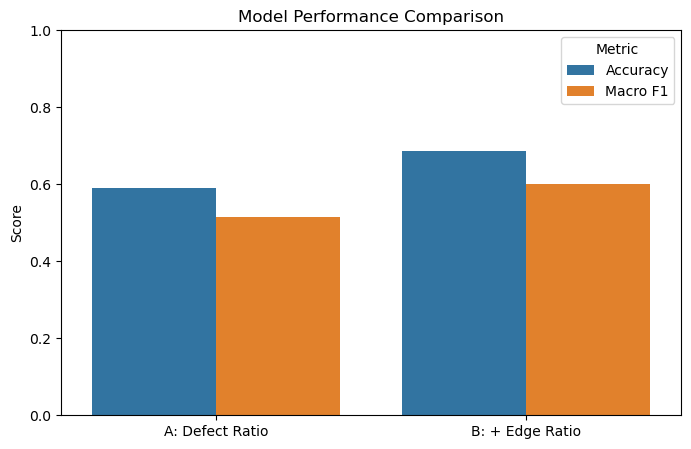

In [12]:
results_plot = results.melt(
    id_vars='Model',
    value_vars=['Accuracy', 'Macro F1'],
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=results_plot,
    x='Model',
    y='Score',
    hue='Metric'
)

plt.ylim(0, 1)
plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.xlabel('')
plt.show()

이 그래프를 보고 새로운 특성이 전체 성능을 얼마나 변화시켰는지 확인하세요.

성능 차이가 작더라도 의미 없는 결과라고 단정하지 마세요.

이미 기존 특성이 충분한 정보를 제공하고 있을 수도 있고, 추가한 특성이 특정 클래스에서만 도움이 되었을 수도 있습니다.

## 활동 C. 어떤 불량 유형에서 성능이 달라졌을까?

### 1. 혼동행렬 비교하기

전체 정확도만으로는 모델이 어떤 불량 유형을 잘 분류했는지 확인하기 어렵습니다.

혼동행렬(Confusion Matrix)을 이용하면 실제 불량 유형과 예측한 유형의 관계를 볼 수 있습니다.

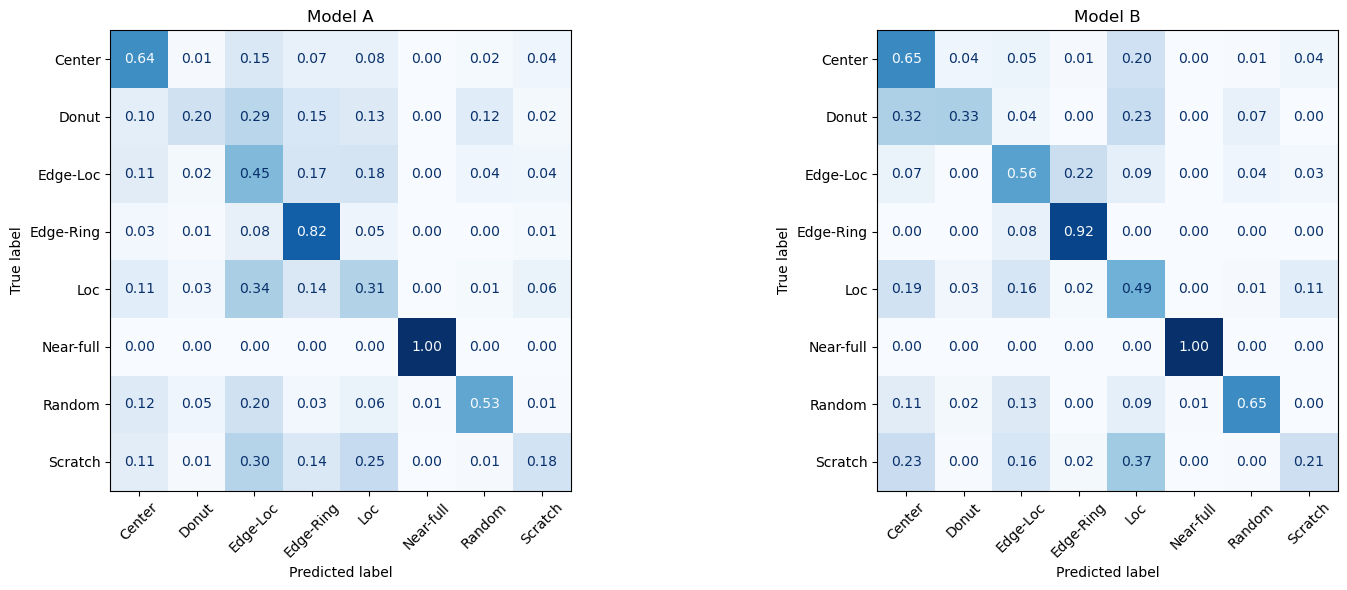

In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

labels = sorted(y.unique())

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, pred, title in zip(
    axes,
    [pred_A, pred_B],
    ['Model A', 'Model B']
):
    cm = confusion_matrix(
        y_test,
        pred,
        labels=labels,
        normalize='true'
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=labels
    )

    disp.plot(
        ax=ax,
        cmap='Blues',
        values_format='.2f',
        colorbar=False
    )

    ax.set_title(title)
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

이번에는 혼동행렬을 `normalize='true'`로 정규화했습니다.

각 실제 클래스의 샘플 수가 서로 다르기 때문에, 클래스별 비율로 비교하기 위해서입니다.

혼동행렬에서 행은 실제 불량 유형, 열은 모델이 예측한 유형입니다.

대각선의 값이 높을수록 해당 유형을 올바르게 분류한 비율이 높습니다.

**Q10.**필수 기록

모델 A와 B의 혼동행렬을 비교해 보세요.

- 성능이 가장 크게 개선된 불량 유형은 무엇인가요?
- 성능이 오히려 낮아진 유형이 있나요?
- `edge_ratio`가 특히 유용했을 것으로 생각되는 유형은 무엇인가요?

각 질문에 대해 실제 결과를 근거로 설명해 보세요.

**답변:**

- **가장 크게 개선된 유형:** Loc의 Recall이 **30.88% → 48.82%**, 약 17.94%p 상승했습니다.
- **Recall이 낮아진 유형:** 없음.
- **특히 유용했던 비교:** Edge-Ring의 Recall도 **82.02% → 91.89%**로 높아져, `edge_ratio`가 외곽 집중 패턴과 다른 패턴을 구분하는 데 도움을 주었습니다.

### 2. 클래스별 성능 비교하기

혼동행렬에서 확인한 내용을 더 자세히 분석하기 위해 클래스별 평가 결과를 출력하겠습니다.

In [14]:
from sklearn.metrics import classification_report

print("=== Model A ===")
print(
    classification_report(
        y_test,
        pred_A,
        zero_division=0
    )
)

print("\n=== Model B ===")
print(
    classification_report(
        y_test,
        pred_B,
        zero_division=0
    )
)

=== Model A ===
              precision    recall  f1-score   support

      Center       0.65      0.64      0.64       859
       Donut       0.23      0.20      0.21       111
    Edge-Loc       0.41      0.45      0.43      1038
   Edge-Ring       0.80      0.82      0.81      1936
         Loc       0.34      0.31      0.32       719
   Near-full       0.97      1.00      0.98        30
      Random       0.51      0.53      0.52       173
     Scratch       0.23      0.18      0.20       238

    accuracy                           0.59      5104
   macro avg       0.52      0.52      0.52      5104
weighted avg       0.58      0.59      0.59      5104


=== Model B ===
              precision    recall  f1-score   support

      Center       0.64      0.65      0.65       859
       Donut       0.37      0.33      0.35       111
    Edge-Loc       0.61      0.56      0.58      1038
   Edge-Ring       0.88      0.92      0.90      1936
         Loc       0.47      0.49      0.48  

각 클래스의 Precision, Recall, F1-score를 비교할 수 있습니다.

- **Precision(정밀도):** 해당 클래스로 예측한 샘플 중 실제로 맞힌 비율
- **Recall(재현율):** 실제 해당 클래스인 샘플 중 올바르게 찾아낸 비율
- **F1-score:** 정밀도와 재현율을 함께 고려한 지표

이번 실습에서는 특히 클래스별 Recall과 F1-score 변화에 주목해 보세요.

**Q11.**

전체 정확도가 상승했더라도 특정 클래스의 Recall이 낮아질 수 있을까요? 실제 결과에서 그런 사례가 있는지 확인해 보세요.

**답변:**

네, 전체 정확도가 높아져도 특정 유형의 Recall은 낮아질 수 있습니다. 다만 **이번 결과에서는 Recall이 낮아진 유형이 없었고**, Near-full을 제외한 유형은 모두 상승했습니다.

### 3. 새로운 특성은 얼마나 중요했을까?

RandomForest는 학습한 모델에서 특성 중요도(Feature Importance)를 확인할 수 있습니다.

In [15]:
importance = pd.DataFrame({
    'Feature': X_B.columns,
    'Importance': model_B.feature_importances_
})

display(
    importance.sort_values(
        'Importance',
        ascending=False
    )
)

,Feature,Importance
1,edge_ratio,0.501997
0,defect_ratio,0.498003


특성 중요도는 모델이 분류 과정에서 각 특성을 얼마나 활용했는지 살펴보는 지표입니다.

다만 RandomForest의 기본 특성 중요도는 학습 과정에서 불순도를 얼마나 감소시켰는지를 기준으로 계산합니다.

따라서 중요도가 높다는 사실만으로 그 특성이 반드시 분류 성능을 개선했다고 판단할 수는 없습니다.

특히 두 특성이 서로 비슷한 정보를 담고 있다면 중요도가 나뉘어 나타날 수도 있습니다.

**Q12.**

두 특성 중 중요도가 높은 것은 무엇인가요? 특성 중요도와 실제 모델 성능 변화를 함께 고려했을 때 어떤 결론을 내릴 수 있을까요?

**답변:**

중요도는 **`edge_ratio` 약 0.5020**, `defect_ratio` 약 0.4980으로 거의 비슷하며 `edge_ratio`가 조금 높습니다. 두 평가 지표도 상승했으므로 이번 실험에서 새 특성이 유용했다고 볼 수 있지만, 중요도만으로 효과를 단정할 수는 없습니다.

## 활동 D. 실험 조건을 바꾸면 어떤 일이 생길까?

### 1. 난수 시드를 변경해 보기

이번 실험에서는 난수 시드를 42로 고정했습니다.

그렇다면 난수 시드를 바꾸면 결과도 달라질까요?

다음 코드는 모델 B에서 사용한 특성은 그대로 유지하면서 학습·테스트 데이터 분할에 사용하는 난수 시드만 바꿉니다.

In [16]:
seed_results = []

for seed in [10, 21, 42, 100]:
    tr_idx, te_idx = train_test_split(
        np.arange(len(df)),
        test_size=0.2,
        random_state=seed,
        stratify=y
    )

    model = RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    model.fit(
        X_B.iloc[tr_idx],
        y.iloc[tr_idx]
    )

    preds = model.predict(X_B.iloc[te_idx])

    seed_results.append({
        'Seed': seed,
        'Accuracy': accuracy_score(y.iloc[te_idx], preds),
        'Macro F1': f1_score(
            y.iloc[te_idx],
            preds,
            average='macro'
        )
    })

seed_df = pd.DataFrame(seed_results)

display(seed_df.round(4))

,Seed,Accuracy,Macro F1
0,10,0.6830,0.6025
1,21,0.6900,0.6122
2,42,0.6853,0.6020
3,100,0.6869,0.6080


이번 코드에서는 모델 자체의 `random_state`는 42로 유지하고, 데이터 분할에 사용하는 시드만 변경했습니다.

따라서 결과가 달라진다면 학습·테스트 데이터 구성의 변화가 영향을 주었을 가능성을 살펴볼 수 있습니다.

다만 학습 데이터가 바뀌면서 모델의 학습 결과도 함께 달라집니다.

**Q13.**

시드를 변경했을 때 성능이 완전히 같았나요? 달라졌다면 무엇이 달라졌기 때문이라고 생각하나요?

**답변:**

같지 않았습니다. 분할 시드에 따라 정확도는 약 **68.26~68.89%**, Macro F1은 약 **0.6020~0.6159**로 달라졌습니다. 모델 시드는 42로 유지했지만 학습·테스트 샘플 구성이 달라졌기 때문입니다.

**Q14.**필수 기록

어떤 시드에서는 모델의 성능이 높고 다른 시드에서는 낮게 나왔다고 가정해 봅시다.

이 중 가장 높은 결과만 선택해 보고하면 어떤 문제가 발생할 수 있을까요?

**답변:**

가장 높은 결과만 보고하면 **우연히 유리했던 분할을 골라 성능을 과장**할 수 있습니다. 여러 시드의 결과와 평균·변동을 함께 보고해야 합니다.

### 2. 실험 결과를 어떻게 해석해야 할까?

머신러닝 실험에서는 성능이 향상되었다는 사실만큼이나 **어떤 조건에서 향상되었는지**가 중요합니다.

이번 실험에서는 기준 모델 A와 비교 모델 B의 학습·테스트 데이터와 모델 설정을 동일하게 유지했습니다.

이를 통해 새로운 특성의 추가가 성능에 어떤 영향을 주었는지 비교할 수 있었습니다.

하지만 이번 결과만으로 모든 데이터에서 동일한 효과가 나타난다고 결론 내릴 수는 없습니다.

특히 이번 WM-811K 데이터에는 다음과 같은 특징이 있습니다.

- 불량 유형별 데이터 개수가 크게 다릅니다.
- 일부 웨이퍼는 같은 제조 로트에서 수집되었을 수 있습니다.
- 이번 실험은 무작위로 나눈 하나의 테스트 데이터셋을 이용했습니다.

같은 로트의 웨이퍼가 학습과 테스트에 모두 포함되면 서로 비슷한 데이터를 평가하는 문제가 발생할 수도 있습니다. 따라서 실제 산업 현장에서 사용할 모델이라면 로트별 데이터 분리 등 더 엄격한 평가도 필요할 수 있습니다.

이번 미션에서는 특성의 효과를 비교하는 방법을 익히기 위해 무작위 분할을 사용합니다.

## 미션 02 결과 정리

이번 미션에서는 같은 머신러닝 알고리즘에 서로 다른 특성 조합을 입력하여 분류 성능을 비교했습니다.

| 항목 | 기준 모델 A | 비교 모델 B |
| --- | --- | --- |
| 입력 특성 | defect_ratio | defect_ratio, edge_ratio |
| 모델 | RandomForest | RandomForest |
| 데이터 분할 | 80:20 | 80:20 |
| 난수 시드 | 42 | 42 |
| Accuracy | 실험 결과 기록 | 실험 결과 기록 |
| Macro F1 | 실험 결과 기록 | 실험 결과 기록 |

이제 새로운 특성의 효과에 대해 자신의 결론을 작성해 보세요.

### Q15. 필수 기록 실험의 종합 결론

다음 내용을 포함하여 5~8문장 정도로 작성해 보세요.

1. 새로운 특성을 추가한 후 전체 분류 성능은 어떻게 변했나요?
2. 어떤 불량 유형에서 가장 뚜렷한 변화가 나타났나요?
3. 이러한 변화가 나타난 이유는 무엇이라고 생각하나요?
4. 실험을 통해 알게 된 점이나 실험의 한계는 무엇인가요?

성능이 개선되지 않았더라도 괜찮습니다. 중요한 것은 결과를 바꾸는 것이 아니라 관찰한 결과를 근거로 설명하는 것입니다.

**답변:**

1. 정확도는 **58.95%에서 68.53%로 약 9.58%p 상승**했습니다. Macro F1은 **0.5159에서 0.6020으로 상승**했습니다.

2. **Loc**에서 가장 뚜렷한 변화가 나타났으며, Recall이 **30.88%에서 48.82%로 약 17.94%p 상승**했습니다.

3. `edge_ratio`가 불량의 가장자리 집중 정보를 추가하여, 전체 불량률이 비슷한 유형을 구분하는 데 도움을 준 것으로 보입니다.

4. 이번 실험을 통해 위치 정보 변수가 유의미하다는 점을 확인했습니다. 다만 데이터 분할 방식에 따라 결과 편차가 있고, 동일 로트의 웨이퍼가 학습과 테스트 데이터에 섞일 수 있어 추가 검증이 필요합니다.

### 결과 저장하기

실험 결과를 다음 미션에서 활용할 수 있도록 저장합니다.

In [17]:
results.to_csv(
    data_dir / 'feature_comparison.csv',
    index=False
)

`feature_comparison.csv`에는 모델 A와 모델 B의 성능 비교 결과가 저장됩니다.

다음 미션에서는 새로운 특성을 직접 설계하고 추가하여 모델 C를 만들 것입니다.

모델 C는 **모델 B에 학생이 선택한 특성을 추가한 모델**입니다.

따라서 개인 실험에서는 이번에 사용한 `train_idx`, `test_idx`, 모델 설정을 동일하게 유지해야 합니다.

Colab에서 실습을 이어서 진행할 예정이라면 현재 노트북도 저장해 두세요. CSV 파일에는 성능 결과만 기록되며, 학습된 모델이나 데이터 분할 인덱스는 포함되지 않습니다.

## 완료 확인

- 미션 01의 특성 데이터를 불러왔다.
- 동일한 학습·테스트 데이터 분할을 만들었다.
- 기준 모델 A를 학습하고 성능을 평가했다.
- `edge_ratio`를 추가한 모델 B를 학습했다.
- 두 모델의 Accuracy와 Macro F1-score를 비교했다.
- 혼동행렬과 클래스별 성능을 확인했다.
- 난수 시드를 바꾸었을 때 나타나는 변화를 관찰했다.
- 실험 결과에 대한 종합 결론을 작성했다.

### 보고서에 기록할 내용

워크북의 모든 질문에 답할 필요는 없습니다.

**[필수 기록]**으로 표시된 질문은 실험 보고서를 작성할 때 활용할 수 있도록 답을 남겨 두세요. 다른 질문은 코드를 이해하고 결과를 해석하기 위한 학습 활동입니다.

이번 미션에서 보관할 결과는 다음과 같습니다.

1. 모델 A와 B의 입력 특성과 실험 조건
2. Accuracy와 Macro F1-score 비교표
3. 두 모델의 혼동행렬과 클래스별 성능 분석
4. 새로운 특성의 효과에 대한 종합 결론
5. 실험 조건 통제 및 재현성에 대한 설명

**마지막으로 생각해 보기**

모델의 성능이 좋아졌다는 사실은 새로운 특성이 유용할 가능성을 보여줍니다.

하지만 그 결과를 신뢰하려면 실험 조건이 공정했는지, 다른 데이터에서도 비슷한 결과가 나타날지 함께 생각해야 합니다.

특성공학은 단순히 열을 추가하는 작업이 아닙니다.

**데이터에 대한 가설을 세우고, 실험으로 검증하고, 결과를 해석하는 과정**입니다.